# Binance hourly price descriptive analysis

This notebook provides a descriptive profile of the 40 USDT-quoted pairs in the approved expanded Binance Spot hourly collection. It analyzes each asset over its own observed span through `2026-09-01 23:00 UTC`, using the immutable gzip-compressed CSV files as the canonical source.

The analysis covers the hourly `open`, `high`, `low`, and `close` price levels. No observation is interpolated, forward-filled, backfilled, or synthesized. Opening and closing prices are plotted at their original hourly frequency for every asset.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display


def find_repository_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root.")


REPOSITORY_ROOT = find_repository_root(Path.cwd().resolve())
SOURCE_DIRECTORY = REPOSITORY_ROOT / "src"
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))

from tcc_crypto.hourly_price_descriptive_analysis import (
    load_analysis_config,
    run_descriptive_analysis,
)

CONFIG_PATH = (
    REPOSITORY_ROOT
    / "configs"
    / "binance_hourly_price_descriptive_analysis.json"
)
analysis_config, collection_config = load_analysis_config(
    CONFIG_PATH, repository_root=REPOSITORY_ROOT
)

configuration_summary = pd.DataFrame(
    {
        "Item": [
            "Analysis ID",
            "Trading pairs",
            "Price fields",
            "Frequency",
            "Requested collection end (UTC)",
            "Output directory",
        ],
        "Value": [
            analysis_config.analysis_id,
            len(collection_config.symbols),
            ", ".join(analysis_config.price_fields),
            collection_config.interval,
            collection_config.end_time_utc,
            analysis_config.output_directory.relative_to(REPOSITORY_ROOT),
        ],
    }
)
display(configuration_summary)

,Item,Value
0,Analysis ID,binance_hourly_price_descriptive_analysis_2026...
1,Trading pairs,40
2,Price fields,"open, high, low, close"
3,Frequency,1h
4,Requested collection end (UTC),2026-09-01 23:59:59.999000+00:00
5,Output directory,outputs/binance_hourly_price_descriptive_analysis


## Generate the descriptive artifacts

For every asset, the pipeline validates chronological UTC timestamps, uniqueness, hourly alignment, positive finite prices, and OHLC consistency. It then writes consolidated tables, an overview panel, and one full-resolution PNG chart per symbol.

In [2]:
artifacts = run_descriptive_analysis(
    CONFIG_PATH,
    repository_root=REPOSITORY_ROOT,
)

artifact_summary = pd.DataFrame(
    {
        "Artifact": [
            "Consolidated workbook",
            "Statistics CSV",
            "Coverage CSV",
            "Extrema CSV",
            "Overview figure",
            "Individual figure directory",
        ],
        "Path": [
            artifacts.workbook,
            artifacts.summary_csv,
            artifacts.coverage_csv,
            artifacts.extremes_csv,
            artifacts.overview_figure,
            artifacts.individual_figure_directory,
        ],
    }
)
artifact_summary["Path"] = artifact_summary["Path"].map(
    lambda path: path.relative_to(REPOSITORY_ROOT)
)
display(artifact_summary)

/Users/marcelapsilverio/projetos/tcc_crypto/src/tcc_crypto/hourly_price_descriptive_analysis.py:345: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  overview_figure.savefig(overview_figure_path, dpi=150, bbox_inches="tight")


,Artifact,Path
0,Consolidated workbook,outputs/binance_hourly_price_descriptive_analy...
1,Statistics CSV,outputs/binance_hourly_price_descriptive_analy...
2,Coverage CSV,outputs/binance_hourly_price_descriptive_analy...
3,Extrema CSV,outputs/binance_hourly_price_descriptive_analy...
4,Overview figure,outputs/binance_hourly_price_descriptive_analy...
5,Individual figure directory,outputs/binance_hourly_price_descriptive_analy...


## Coverage and temporal comparability

Assets begin at different listing dates. The table reports each observed span and counts only missing hourly openings inside that span; time before listing is not classified as missing. These differences must remain visible when the descriptive results are discussed.

In [3]:
display(
    artifacts.coverage.style
    .format(
        {
            "Observations": "{:,}",
            "Observed span (days)": "{:,.1f}",
            "Missing hours within observed span": "{:,}",
        }
    )
    .set_caption("Observed hourly price-series coverage by trading pair")
)

,Symbol,Observations,First open (UTC),Last open (UTC),Observed span (days),Missing hours within observed span
0,BTCUSDT,"79,140",2017-08-17 04:00:00+00:00,2026-09-01 23:00:00+00:00,"3,302.8",128
1,FLOKIUSDT,"29,166",2023-05-05 18:00:00+00:00,2026-09-01 23:00:00+00:00,"1,215.2",0
2,ETHUSDT,"79,140",2017-08-17 04:00:00+00:00,2026-09-01 23:00:00+00:00,"3,302.8",128
3,BONKUSDT,"23,800",2023-12-15 08:00:00+00:00,2026-09-01 23:00:00+00:00,991.6,0
4,SOLUSDT,"53,086",2020-08-11 06:00:00+00:00,2026-09-01 23:00:00+00:00,"2,212.7",20
5,XRPUSDT,"72,936",2018-05-04 08:00:00+00:00,2026-09-01 23:00:00+00:00,"3,042.6",88
6,SHIBUSDT,"46,566",2021-05-10 11:00:00+00:00,2026-09-01 23:00:00+00:00,"1,940.5",7
7,DOGEUSDT,"62,728",2019-07-05 12:00:00+00:00,2026-09-01 23:00:00+00:00,"2,615.5",44
8,BNBUSDT,"77,203",2017-11-06 03:00:00+00:00,2026-09-01 23:00:00+00:00,"3,221.8",122
9,ADAUSDT,"73,348",2018-04-17 04:00:00+00:00,2026-09-01 23:00:00+00:00,"3,059.8",88


## Price-level statistics

Standard deviation and variance use the sample definition (`ddof=1`). Quartiles use linear interpolation. Skewness is the unbiased normalized sample skewness, and kurtosis is Fisher excess kurtosis, so a normal distribution has an expected value of zero. Values describe price levels in USDT, not returns.

In [4]:
statistics_format = {
    "Observations": "{:,}",
    "Missing values": "{:,}",
    "Mean (USDT)": "{:,.8g}",
    "Median (USDT)": "{:,.8g}",
    "Standard deviation (USDT)": "{:,.8g}",
    "Variance (USDT squared)": "{:,.8g}",
    "Minimum (USDT)": "{:,.8g}",
    "Q1 (USDT)": "{:,.8g}",
    "Q3 (USDT)": "{:,.8g}",
    "Maximum (USDT)": "{:,.8g}",
    "Range (USDT)": "{:,.8g}",
    "Interquartile range (USDT)": "{:,.8g}",
    "Coefficient of variation (%)": "{:,.2f}",
    "Skewness": "{:,.3f}",
    "Excess kurtosis": "{:,.3f}",
}
display(
    artifacts.summary.style
    .format(statistics_format)
    .set_caption("Descriptive statistics for hourly OHLC price levels")
)

,Symbol,Price field,Observations,Missing values,Mean (USDT),Median (USDT),Standard deviation (USDT),Variance (USDT squared),Minimum (USDT),Q1 (USDT),Q3 (USDT),Maximum (USDT),Range (USDT),Interquartile range (USDT),Coefficient of variation (%),Skewness,Excess kurtosis
0,BTCUSDT,open,"79,140",0,"38,635.908","28,753.315","32,407.776",1.0502639e+09,"2,870.9","9,405.3175","62,684.635","126,011.18","123,140.28","53,279.318",83.88,0.811,-0.448
1,BTCUSDT,high,"79,140",0,"38,789.159","28,897.205","32,503.381",1.0564697e+09,"2,950","9,445","62,888","126,199.63","123,249.63","53,443",83.80,0.809,-0.454
2,BTCUSDT,low,"79,140",0,"38,475.316","28,605.205","32,309",1.0438715e+09,"2,817","9,360.9525","62,456.632","125,252.74","122,435.74","53,095.68",83.97,0.814,-0.442
3,BTCUSDT,close,"79,140",0,"38,636.827","28,758.695","32,407.844",1.0502683e+09,"2,919","9,405.77","62,684.85","126,011.18","123,092.18","53,279.08",83.88,0.811,-0.448
4,FLOKIUSDT,open,"29,166",0,8.4110625e-05,5.7425e-05,6.7761843e-05,4.5916673e-09,1.535e-05,2.94625e-05,0.000127795,0.00033732,0.00032197,9.83325e-05,80.56,1.066,0.226
5,FLOKIUSDT,high,"29,166",0,8.4986793e-05,5.81e-05,6.866906e-05,4.7154398e-09,1.544e-05,2.965e-05,0.000129065,0.000349,0.00033356,9.9415e-05,80.80,1.073,0.250
6,FLOKIUSDT,low,"29,166",0,8.3253034e-05,5.687e-05,6.6876775e-05,4.472503e-09,1.524e-05,2.925e-05,0.0001266975,0.00033243,0.00031719,9.74475e-05,80.33,1.059,0.201
7,FLOKIUSDT,close,"29,166",0,8.4109881e-05,5.7415e-05,6.776218e-05,4.5917131e-09,1.535e-05,2.947e-05,0.000127795,0.00033732,0.00032197,9.8325e-05,80.56,1.066,0.226
8,ETHUSDT,open,"79,140",0,"1,685.0416","1,707.14","1,261.64","1,591,735.4",82.16,352.38,"2,607.8525","4,935.01","4,852.85","2,255.4725",74.87,0.359,-0.956
9,ETHUSDT,high,"79,140",0,"1,694.1868","1,716.545","1,267.8958","1,607,559.9",82.95,354.4175,"2,623.025","4,956.78","4,873.83","2,268.6075",74.84,0.358,-0.957


## Observed minima and maxima

The extrema table connects unusually low and high observed price levels to exact UTC timestamps. It is useful for locating candidate episodes for qualitative discussion, but an isolated hourly extreme does not by itself define a sustained rising or falling market regime.

In [5]:
display(
    artifacts.extremes.style
    .format({"Minimum (USDT)": "{:,.8g}", "Maximum (USDT)": "{:,.8g}"})
    .set_caption("Observed hourly price-level extrema and UTC timestamps")
)

,Symbol,Price field,Minimum (USDT),Minimum timestamp (UTC),Maximum (USDT),Maximum timestamp (UTC)
0,BTCUSDT,open,"2,870.9",2017-09-15 12:00:00+00:00,"126,011.18",2025-10-06 19:00:00+00:00
1,BTCUSDT,high,"2,950",2017-09-15 11:00:00+00:00,"126,199.63",2025-10-06 18:00:00+00:00
2,BTCUSDT,low,"2,817",2017-09-15 11:00:00+00:00,"125,252.74",2025-10-06 19:00:00+00:00
3,BTCUSDT,close,"2,919",2017-09-15 11:00:00+00:00,"126,011.18",2025-10-06 18:00:00+00:00
4,FLOKIUSDT,open,1.535e-05,2023-09-18 01:00:00+00:00,0.00033732,2024-06-05 04:00:00+00:00
5,FLOKIUSDT,high,1.544e-05,2023-09-21 21:00:00+00:00,0.000349,2024-06-05 07:00:00+00:00
6,FLOKIUSDT,low,1.524e-05,2023-09-11 19:00:00+00:00,0.00033243,2024-06-05 07:00:00+00:00
7,FLOKIUSDT,close,1.535e-05,2023-09-18 00:00:00+00:00,0.00033732,2024-06-05 03:00:00+00:00
8,ETHUSDT,open,82.16,2018-12-15 16:00:00+00:00,"4,935.01",2025-08-24 19:00:00+00:00
9,ETHUSDT,high,82.95,2018-12-15 18:00:00+00:00,"4,956.78",2025-08-24 19:00:00+00:00


## Opening- and closing-price series by asset

Every panel uses its asset's own vertical scale because the nominal prices differ by many orders of magnitude. The overview preserves the original hourly observations; individual high-resolution figures are available in the output directory for closer inspection and later use in the monograph.

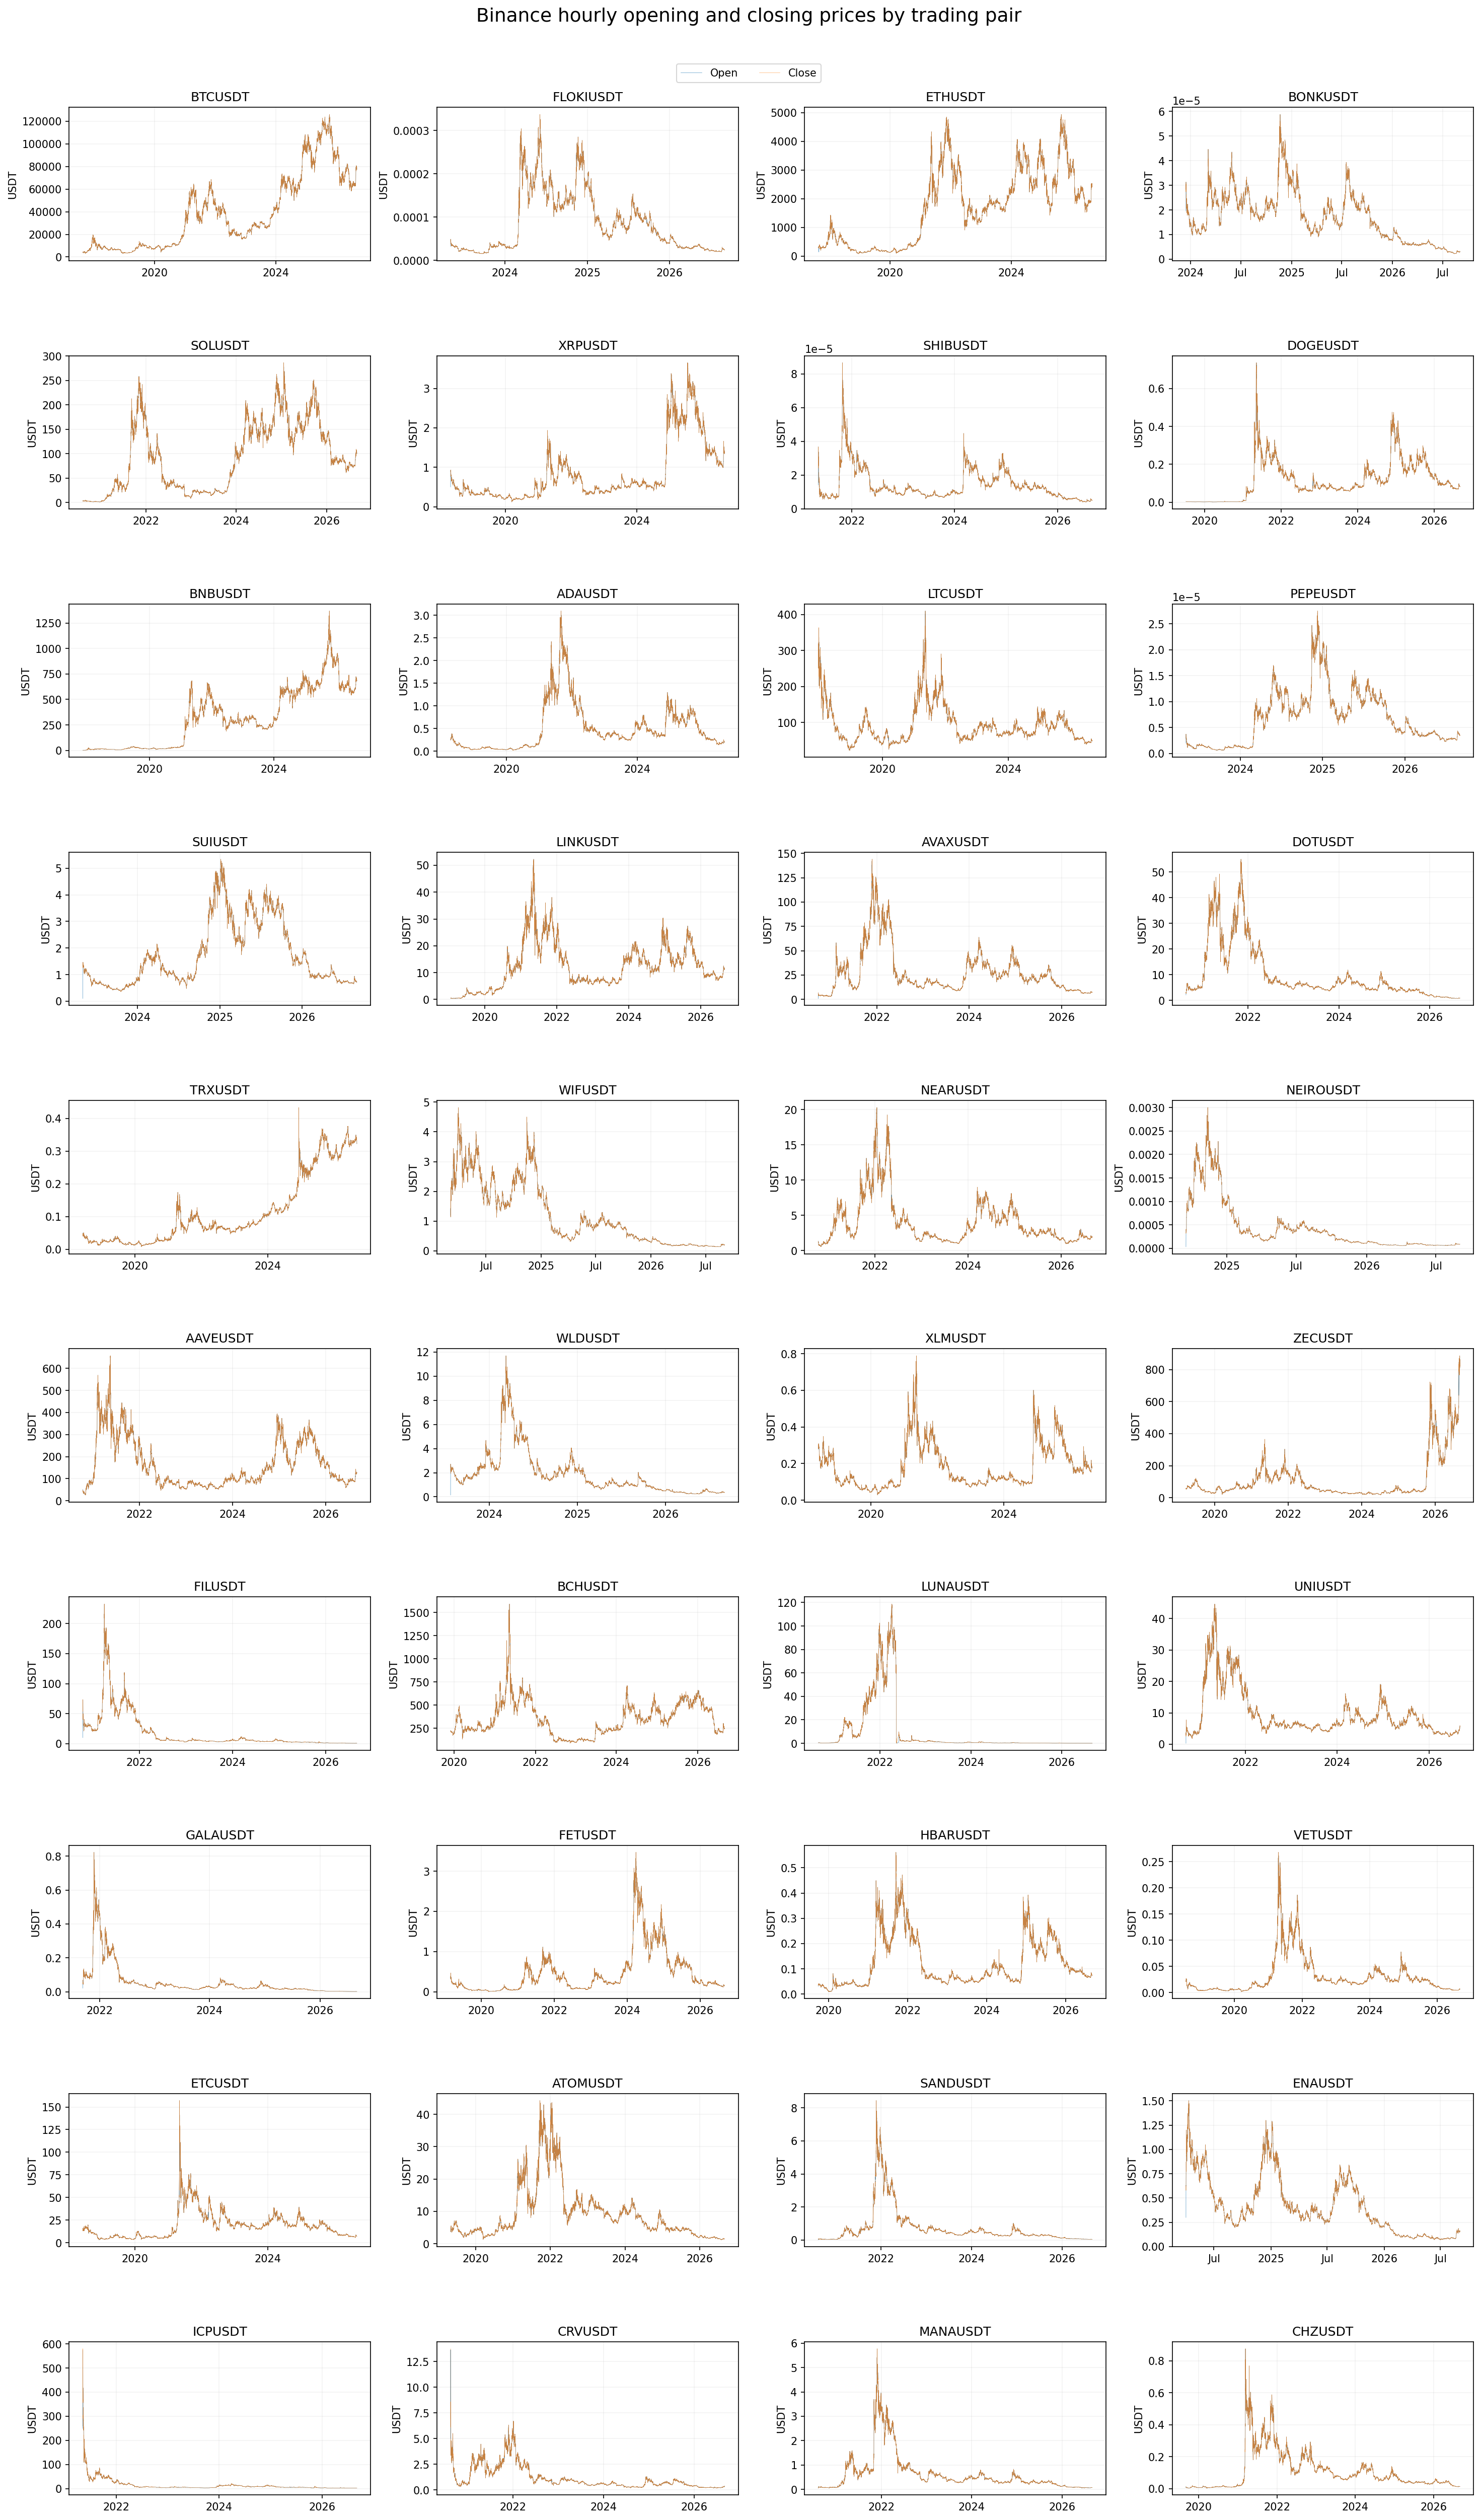

In [6]:
display(Image(filename=str(artifacts.overview_figure)))

## Interpretation limits and next decision

Means, dispersion measures, skewness, and kurtosis of price levels are strongly affected by trends, listing dates, nominal price scales, and extreme episodes. They should not be interpreted as return, volatility, or investment-risk estimates, and cross-asset comparisons require special caution.

The line charts support a qualitative description of periods with relatively high or low prices. Formally labeling sustained bull and bear periods would require a separate rule, such as a drawdown threshold, moving-average criterion, or return over an approved horizon. No such rule is imposed in this notebook.